# SPD model fits

Fitting of SPD model (STD model with multiple TA cell rounds of TA asymmetric division, and TA symmetric division permitted). The figures aren't included in the paper, but the result is mentioned in the Supplementary Note.


## Running fitting: 
### Finding best fits
To find best fits with simulated annealing run: [FitSPD.py](../../modelling/FitSPD.py):
```bash
#Comment out the model use
mode=1 #Use 2D
#mode=0 #Use 0D

# Example usage for simulated annealing:
parallel --max-procs 10 python3.12 FitSPD.py {1} 1 $mode M 1000 0.0 -1.0 0.5 4 1.0 ::: {-580..-541} &
parallel --max-procs 15 python3.12 FitSPD.py {1} 1 $mode M 1000 0.0  1.0 0.5 4 1.0 ::: {-620..-581} &
parallel --max-procs 15 python3.12 FitSPD.py {1} 1 $mode M 1000 1.0  1.0 0.5 4 1.0 ::: {-660..-621} &
parallel --max-procs 10 python3.12 FitSPD.py {1} 1 $mode F 1000 0.0 -1.0 0.5 4 1.0 ::: {-580..-541} &
parallel --max-procs 15 python3.12 FitSPD.py {1} 1 $mode F 1000 0.0  1.0 0.5 4 1.0 ::: {-620..-581} &
parallel --max-procs 15 python3.12 FitSPD.py {1} 1 $mode F 1000 1.0  1.0 0.5 4 1.0 ::: {-660..-621} &
parallel --max-procs 10 python3.12 FitSPD.py {1} 1 $mode c 1000 0.0 -1.0 0.5 4 1.0 ::: {-580..-541} &
parallel --max-procs 15 python3.12 FitSPD.py {1} 1 $mode c 1000 0.0  1.0 0.5 4 1.0 ::: {-620..-581} &
parallel --max-procs 15 python3.12 FitSPD.py {1} 1 $mode c 1000 1.0  1.0 0.5 4 1.0 ::: {-660..-621} &

```

At the end to combine files run:
```bash
#Analyse simulated annealing
python3.12 FitSPD.py -2000 1 0 M 1000 &
python3.12 FitSPD.py -2000 1 0 F 1000 &
python3.12 FitSPD.py -2000 1 0 c 1000 &
```


### Estimating parameter uncertainty with grid search+bootstrapping
To estimate parameter uncertainty run: [FitSTD.py](../../modelling/FitSTD.py):

```bash
#Run bootstrapping over grid
parallel --max-procs 50 python3.12 FitSPD.py {1} 1 $mode M 1000 0.0 1.0 0.5 0 1.0 ::: {0..12000} &
parallel --max-procs 50 python3.12 FitSPD.py {1} 1 $mode F 1000 0.0 1.0 0.5 0 1.0 ::: {0..12000} &
parallel --max-procs 35 python3.12 FitSPD.py {1} 1 $mode c 1000 0.0 1.0 0.5 0 1.0 ::: {0..12000} &


#Analyse grid
python3.12 FitSPD.py -1000 1 0 M 1000 &
python3.12 FitSPD.py -1000 1 0 F 1000 &
python3.12 FitSPD.py -1000 1 0 c 1000 &
```

In [ ]:
#Imports
import numpy as np
import matplotlib.pyplot as plt
import sys

sys.path.append("../../analysis/")
sys.path.append("../../sim/")
sys.path.append("../../fit/")
sys.path.append("../../plot/")



from tissue import *
import tissplot as tplt
import matplotlib.path as mplPath
import datasets as ds 
import tiss_optimize as topt
import sim_model
import custom_metrics as cmet



#Metrics
ksdists  = {'dist': ['S2like.basalCS', 'S2like.supraCS'], 'dist_metric': 'ksd', 'name': 'ksd_b_sb'}
k1dists  = {'dist': ['S2like.basalCS'], 'dist_metric': 'ksd', 'name': 'ksd_bas'}
lldistS  = {'dist': ['S4like.basalCS'], 'dist_metric': 'lLL', 'name': 'll_S_bas'}
ll_dist_SPD = {'dist': ['Slike.fullbasalCS', 'Slike.fullsupraCS',
                    'Tlike.fullbasalCS', 'Tlike.fullsupraCS',
                    'Dlike.fullbasalCS', 'Dlike.fullsupraCS', 
                    'S2like.xfrac'], 
                    'dist_metric': 'lLL', 'name': 'll_SPD'}

ll_dist_SPD = {'dist': ['S4like.fullbasalCS', 'S4like.fullsupraCS',
                    'CPlike.fullbasalCS', 'CPlike.fullsupraCS',
                    'Dlike.fullbasalCS', 'Dlike.fullsupraCS'], 
                    'dist_metric': 'lLL', 'name': 'll_SPD'}
full = {'custom_metrics': {'S4like.fulljointCS': cmet.logLL_joint, 
                           'CPlike.fulljointCS': cmet.logLL_joint, 
                           'Dlike.fulljointCS': cmet.logLL_joint}, 
                           'name': 'full', 
        'exclude_times': {'S2like.fulljointCS': np.arange(6,7)}}

T0 = 50
mets = [ll_dist_SPD, ll_dist_SPD, ksdists, k1dists, lldistS, full] 
compute_kwargs = {'Dlike': {'containsBasal': False}}
toCalculate = ['basalCS', 'S4like.basalCS', 'S4like.supraCS', 'CPlike.basalCS', 'CPlike.supraCS', 'Dlike.basalCS', 'Dlike.supraCS',
               'Tlike.basalCS', 'Tlike.supraCS', 'Slike.basalCS', 'Slike.supraCS', 'S2like.basalCS', 'S2like.supraCS',
               'T3like.basalCS', 'T3like.supraCS', 'S2like.xfrac', 'Slike.xfrac', 'Tlike.xfrac', 'Dlike.xfrac',
               'S4like.lcd', 'T3like.lcd', 'CPlike.lcd', 'Dlike.lcd', 'Slike.lcd', 'Tlike.lcd', 'S2like.lcd',
               'S4like.pers', 'T3like.pers', 'CPlike.pers', 'Dlike.pers', 'Slike.pers', 'Tlike.pers', 'S2like.pers',]


from matplotlib import rcParams
# Set global font size for all axes
rcParams['axes.labelsize'] = 10
rcParams['xtick.labelsize'] = 7.5
rcParams['ytick.labelsize'] = 7.5
rcParams['legend.fontsize'] = 7.5
rcParams['font.size'] = 7.5  # General font size
rcParams['text.usetex'] = False
rcParams['svg.fonttype'] = 'none'
rcParams['lines.markersize']  = 3
rcParams['lines.linewidth']  = 1.5



1 0 M
M 4436.289463429462 ll_SPD
hrun_SPD_0D_t_-30_n_1500_CVd_D_0.95_CVd_P_-1.0_CVd_S_0.5_corrDD_0.7_corrPD_0.0_corrPP_-1.0_corrSP_-1.0_corrSS_0.8_mu_50.0_q_0.875_r_0.15_refractP_-1.0_tau_100.0_seed_0.pkl
tscale: -7.25
τ range: 4.6 to 140.0
shed: -0.6 refract: 0.0 cv: 1.0
Already cropped
Already cropped
Already cropped
Already cropped


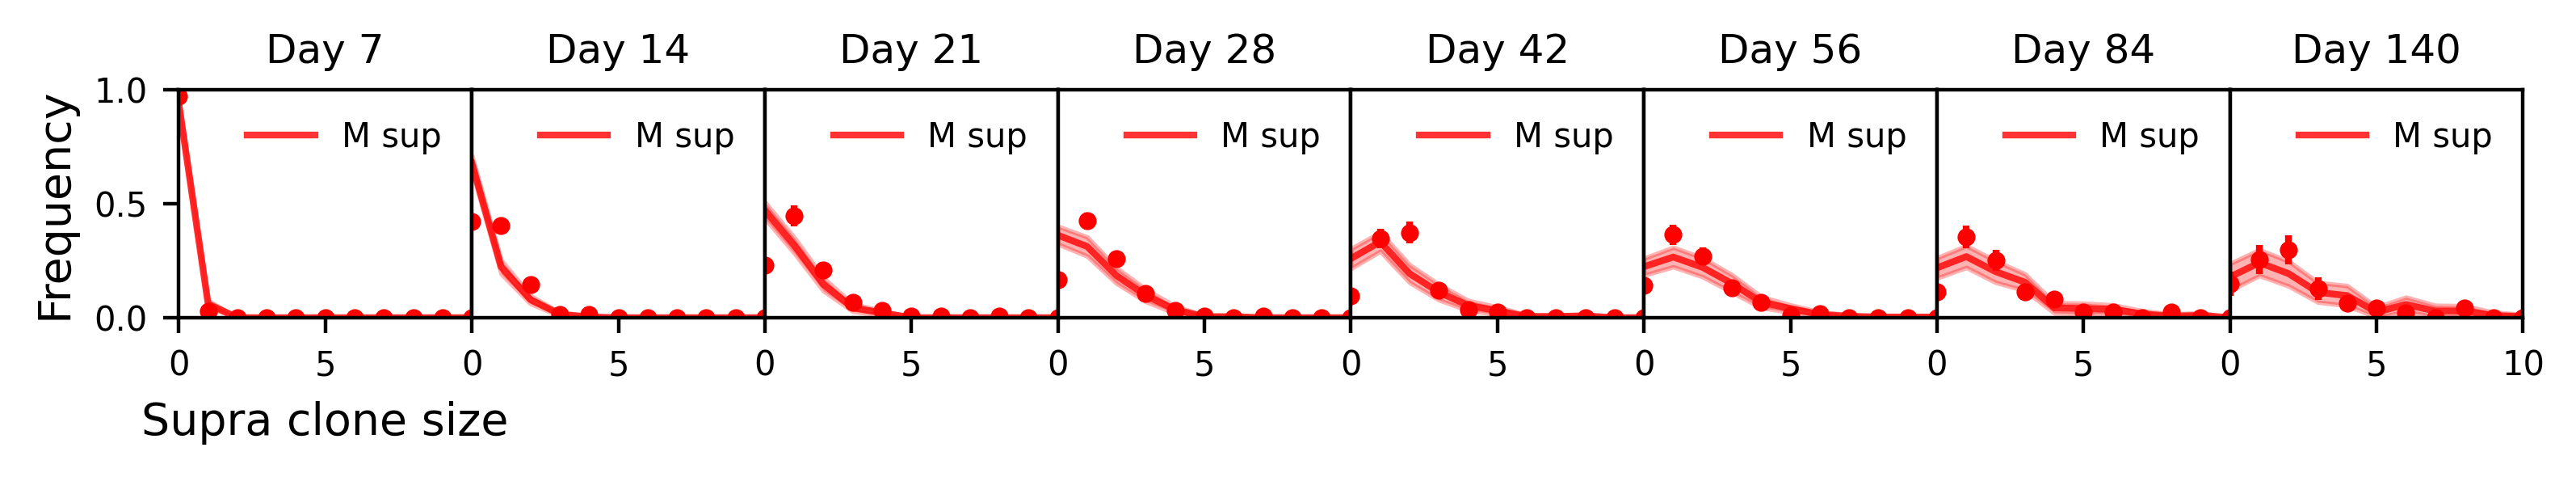

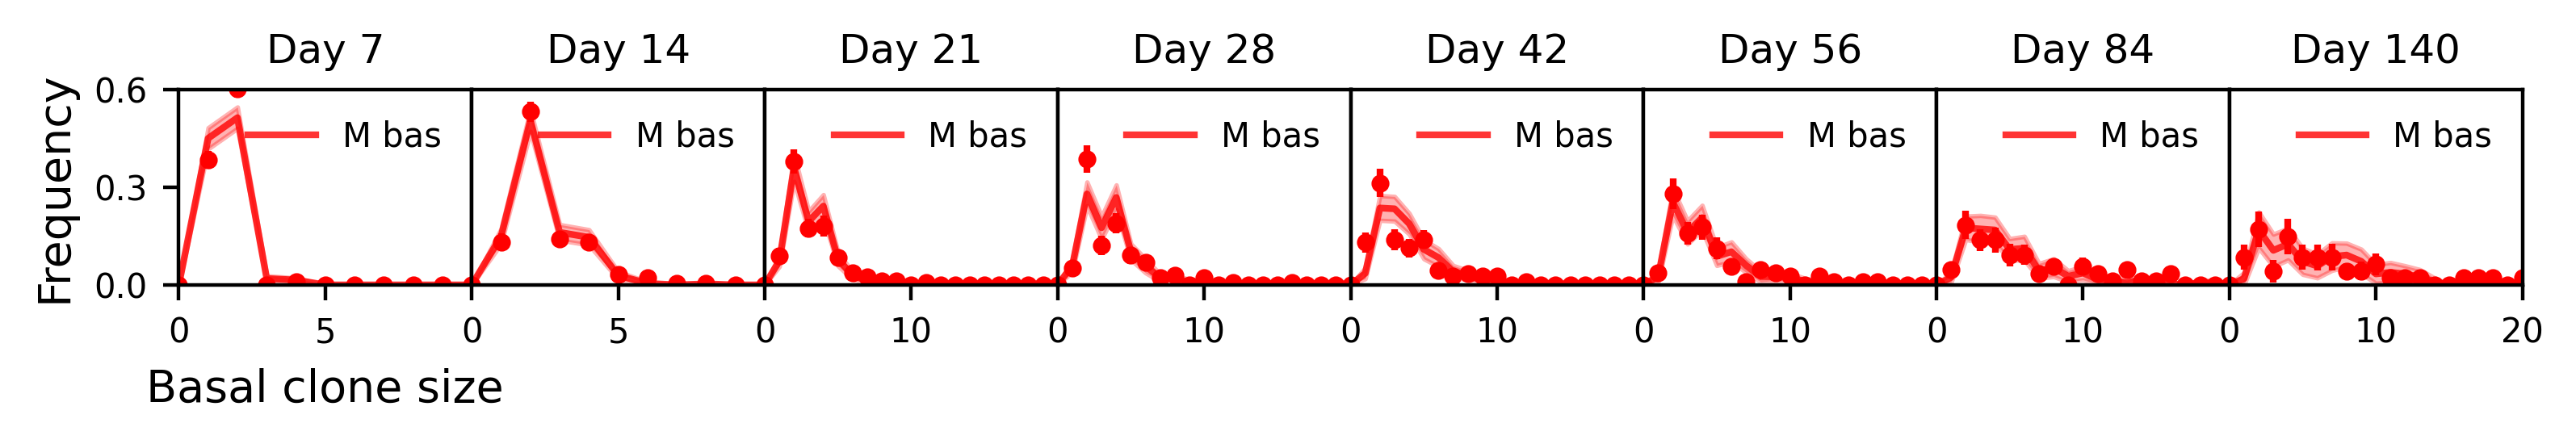

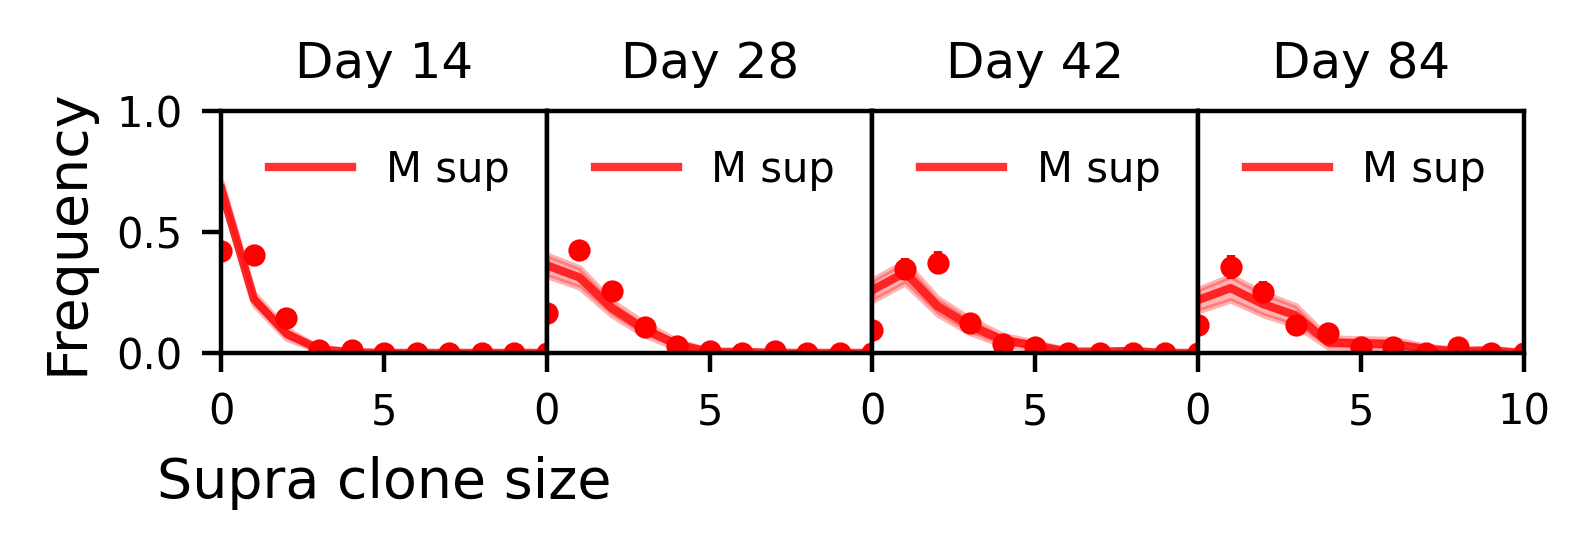

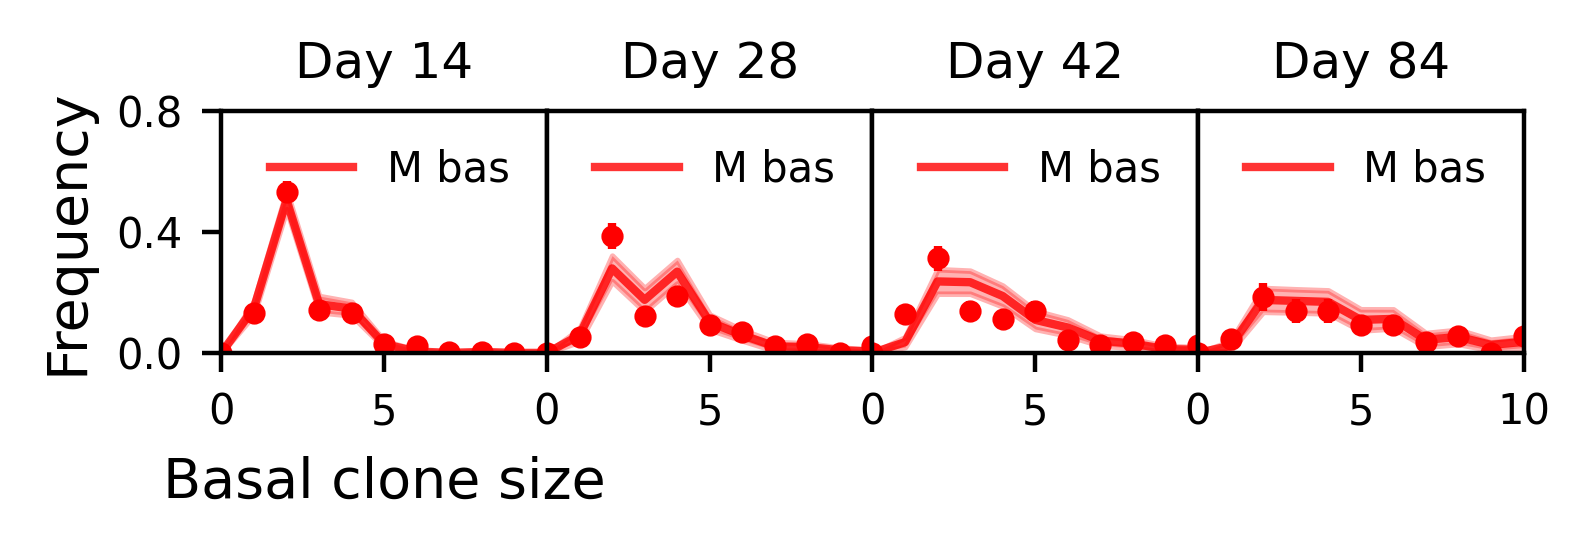

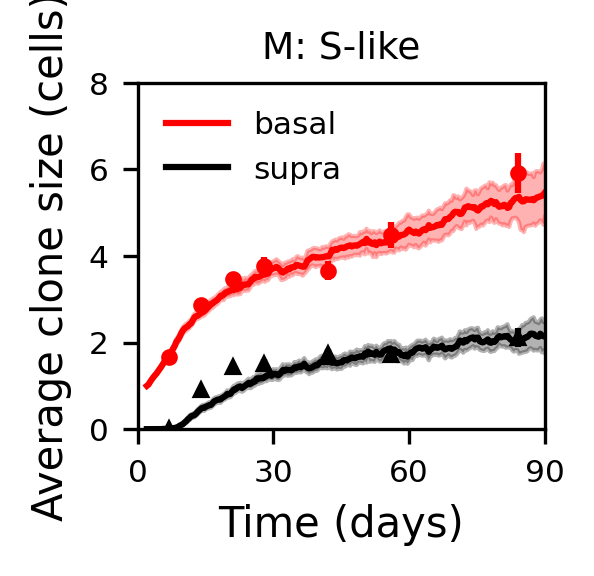

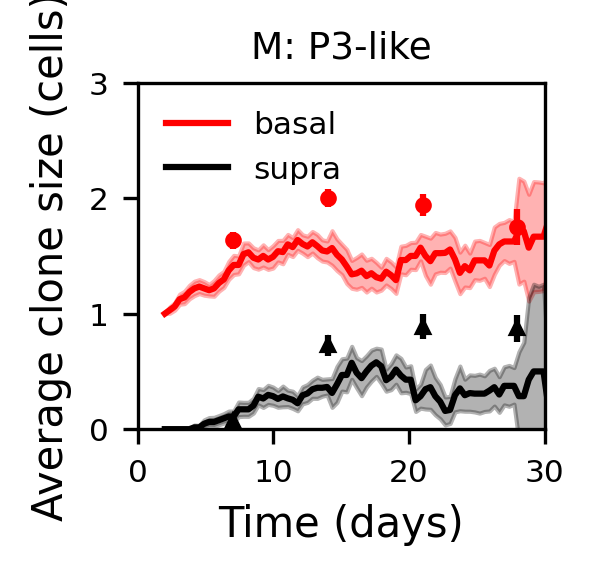

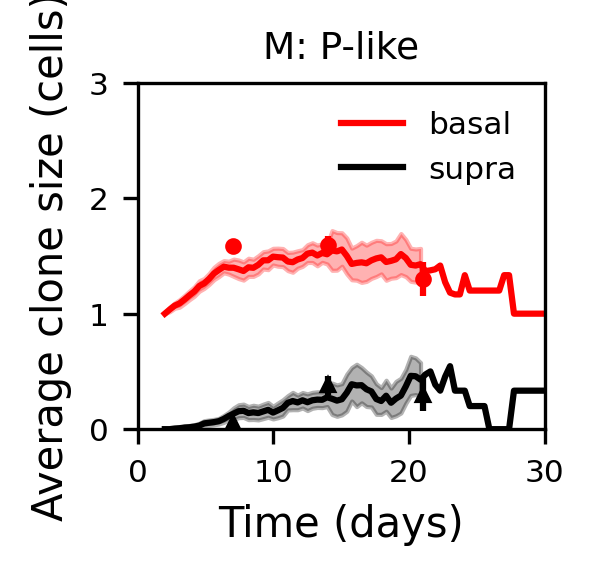

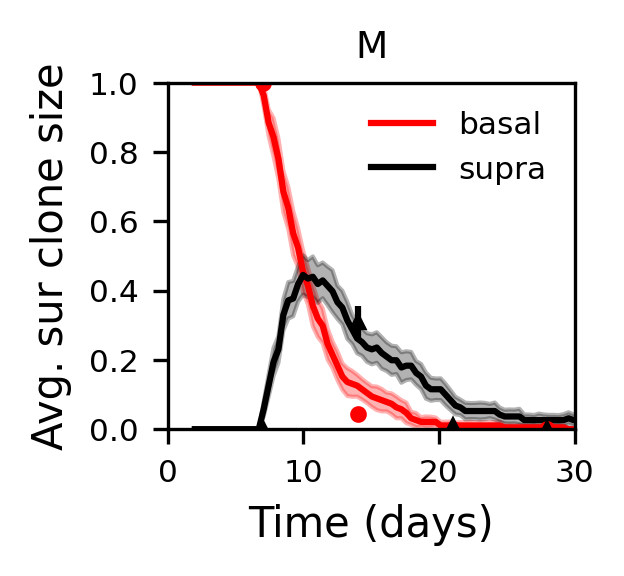

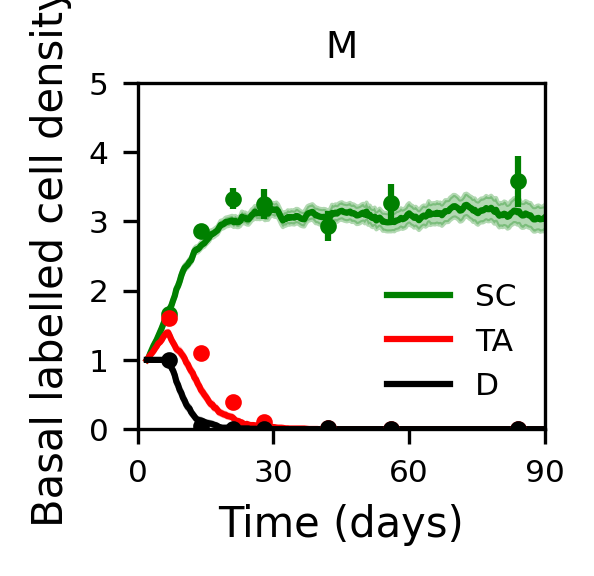

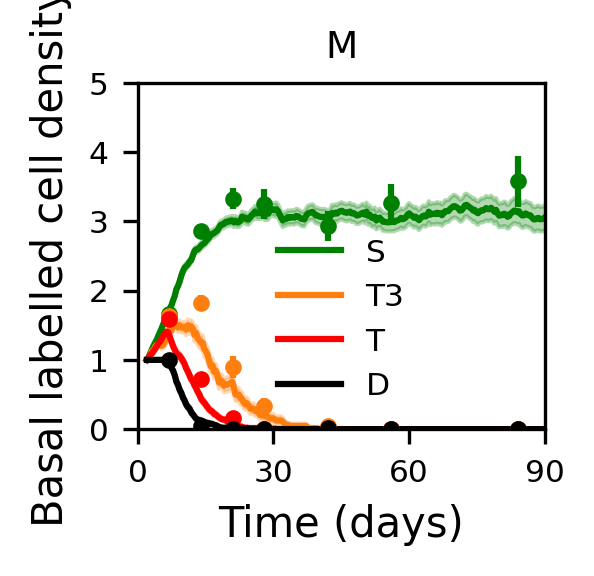

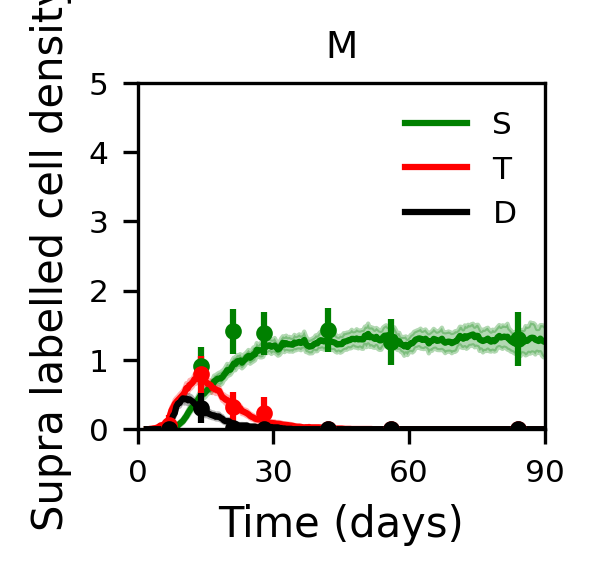

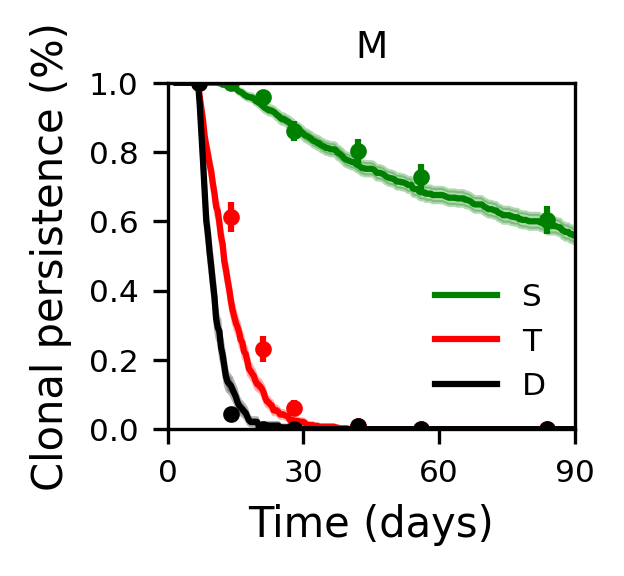

Already cropped


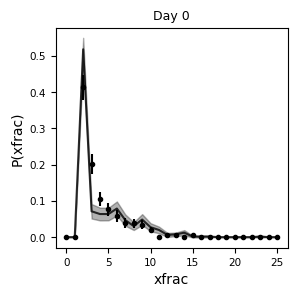




M 4085.743945671061 full
hrun_SPD_0D_t_-30_n_1500_CVd_D_0.95_CVd_P_-1.0_CVd_S_0.5_corrDD_0.3_corrPD_1.0_corrPP_-1.0_corrSP_1.0_corrSS_0.0_mu_50.0_q_0.975_r_0.175_refractP_-1.0_tau_100.0_seed_0.pkl
tscale: -6.35
τ range: 4.6 to 140.0
shed: -0.6 refract: 0.0 cv: 1.0
Already cropped
Already cropped
Already cropped
Already cropped


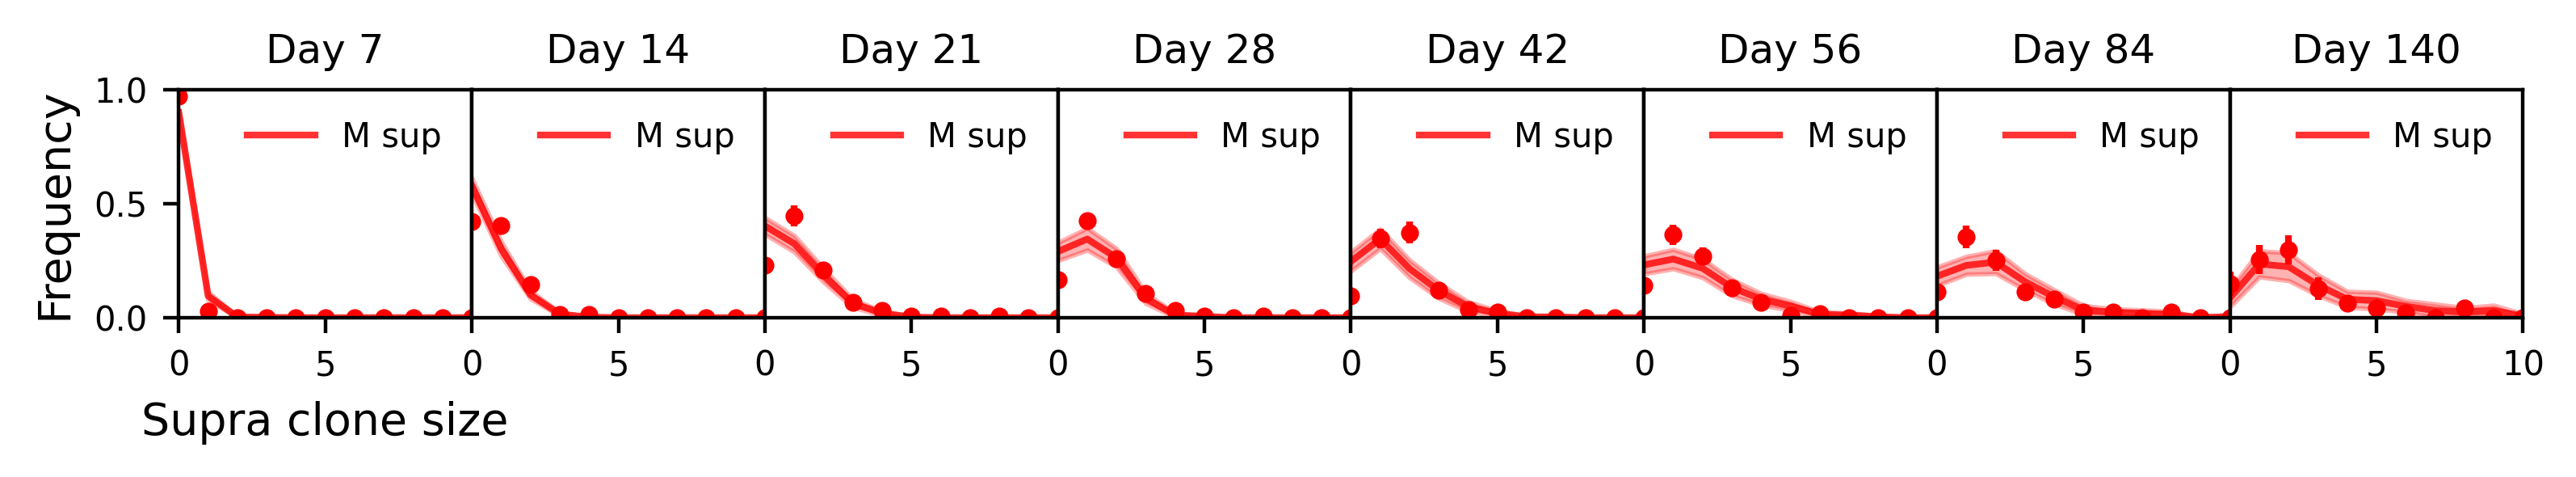

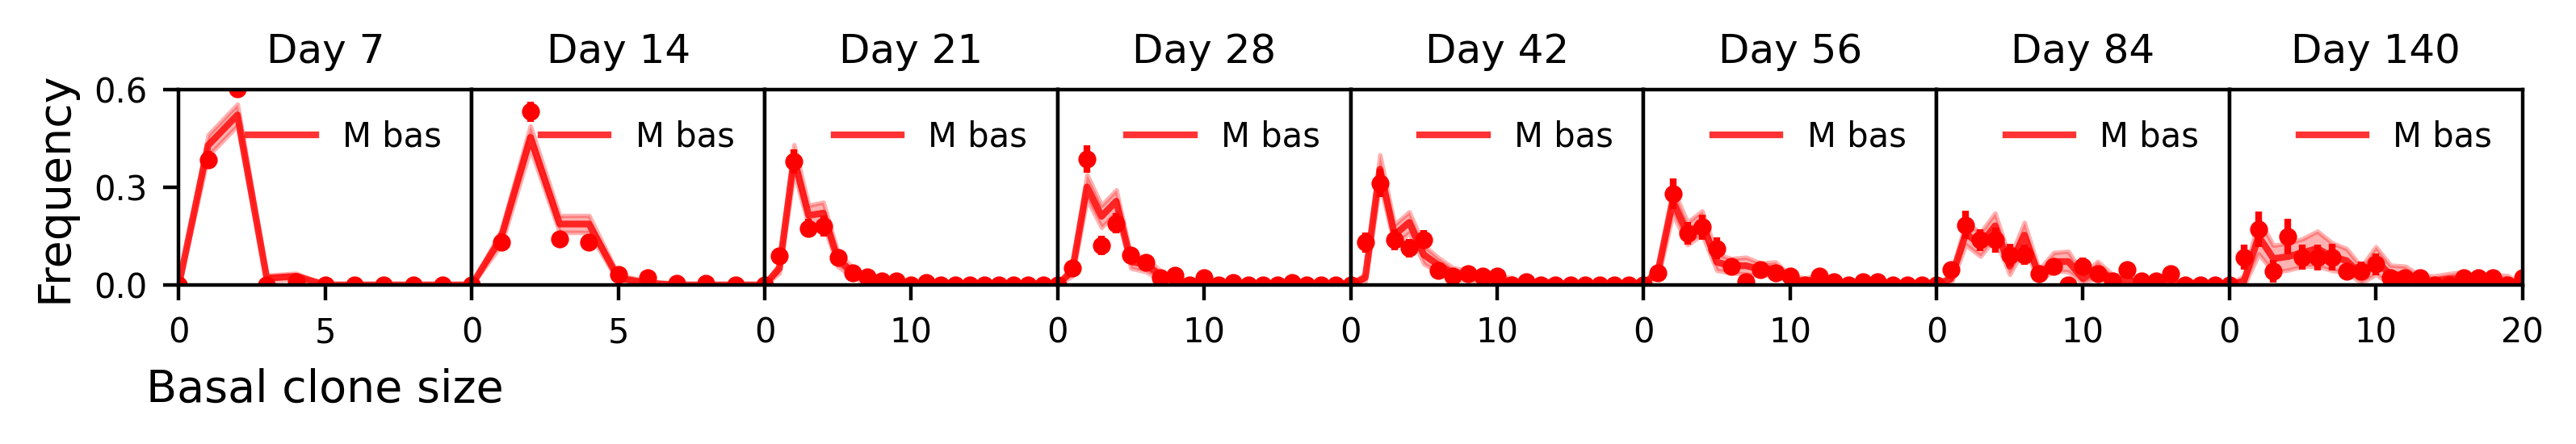

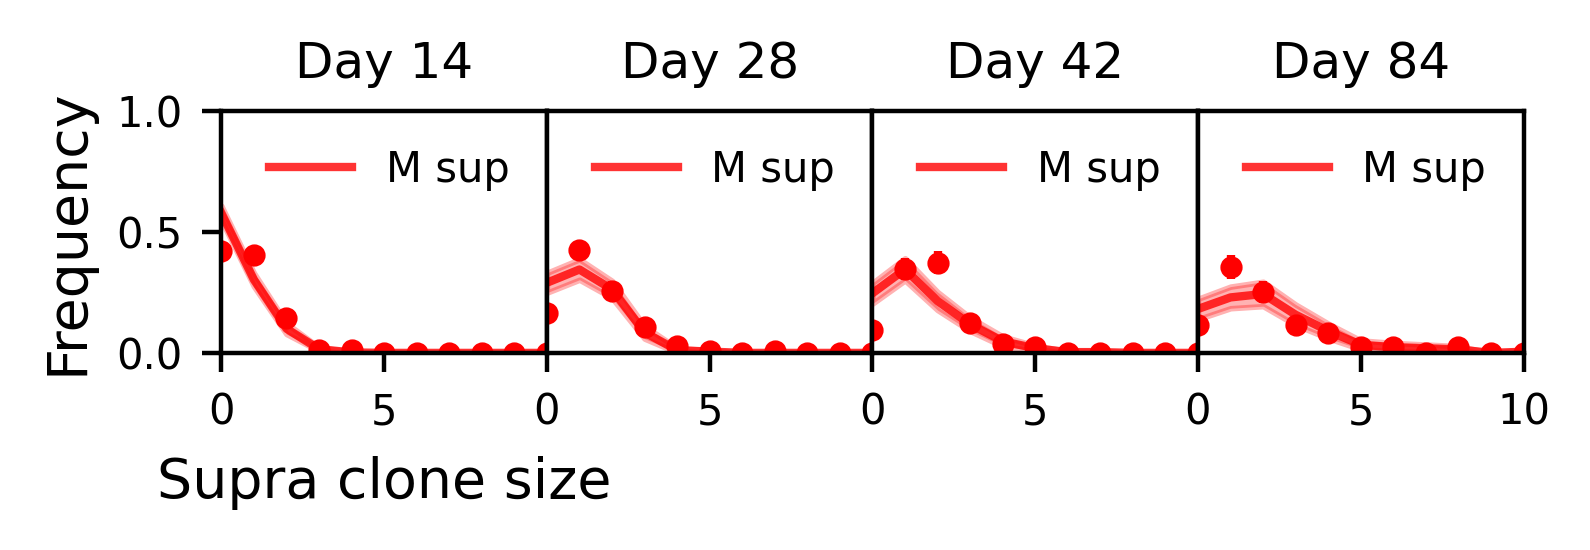

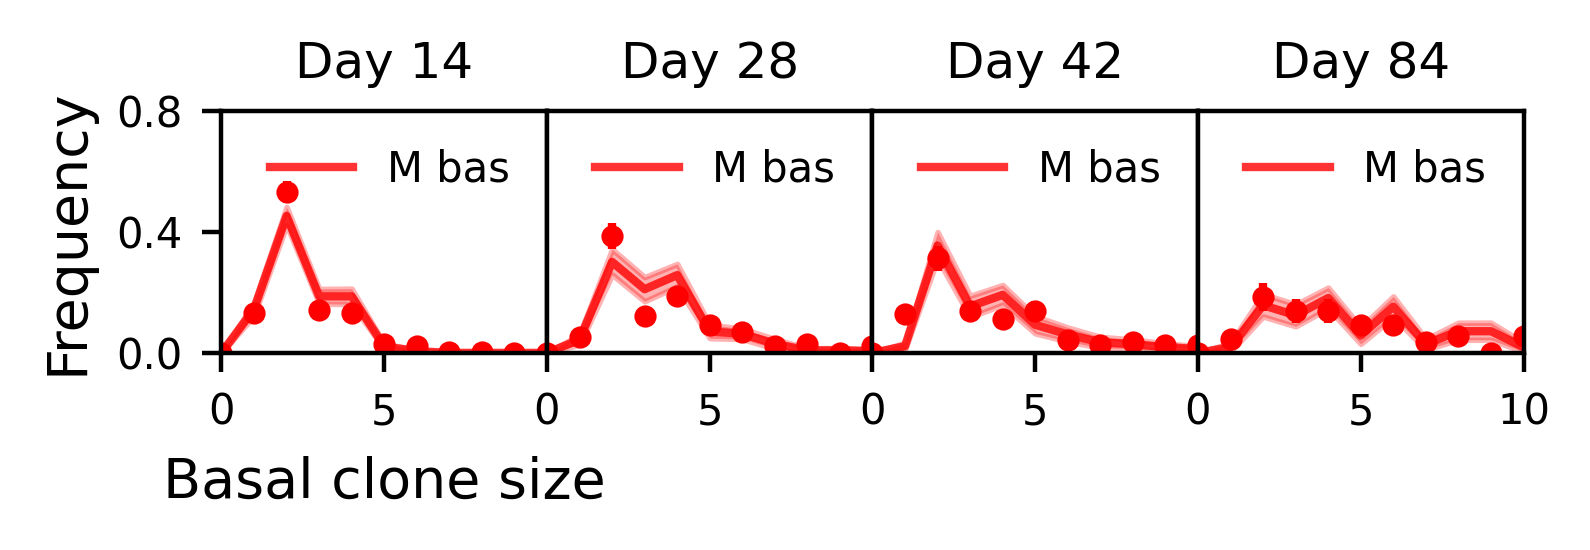

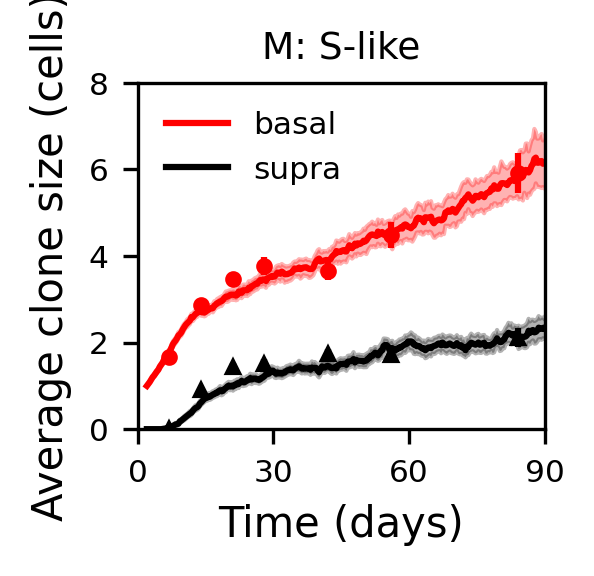

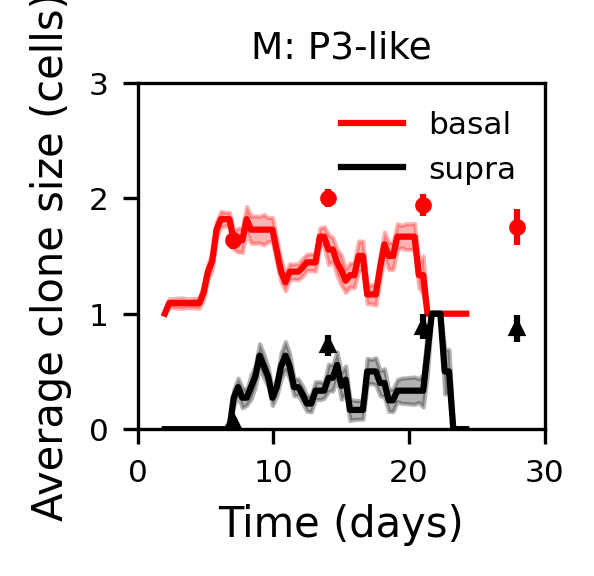

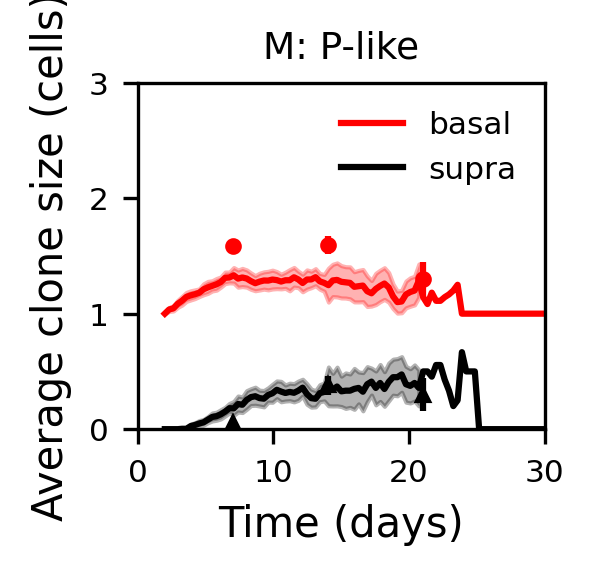

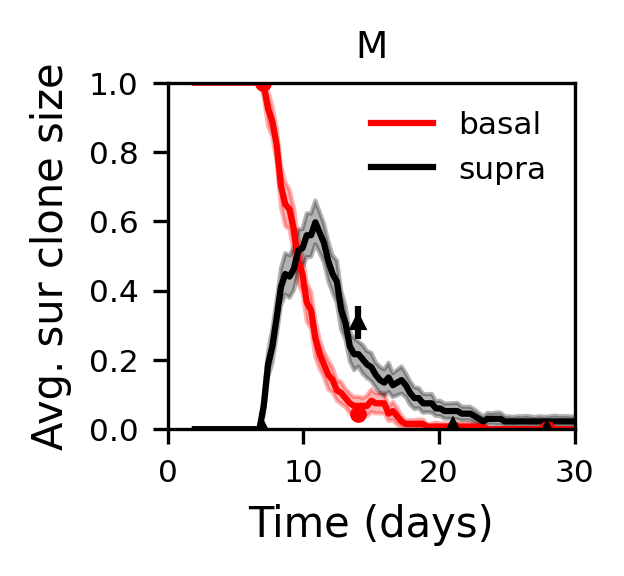

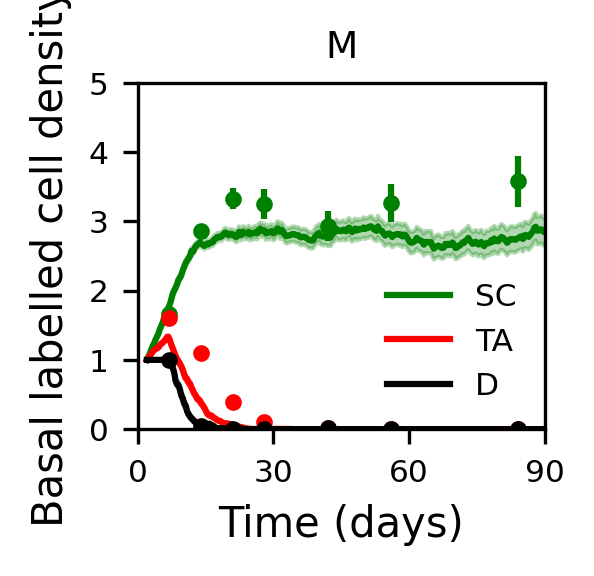

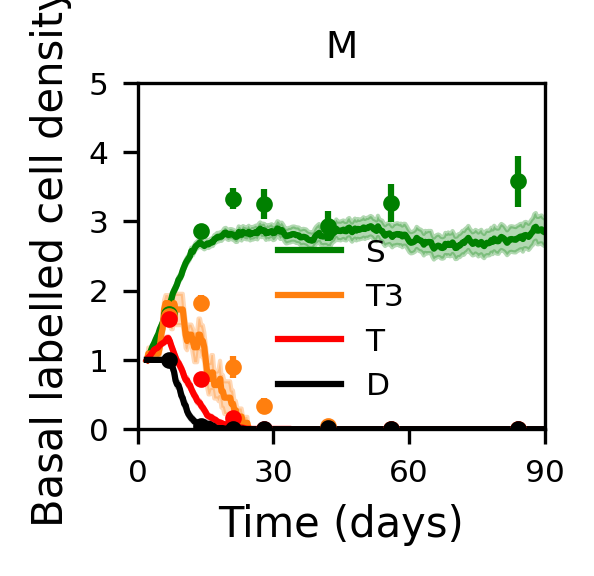

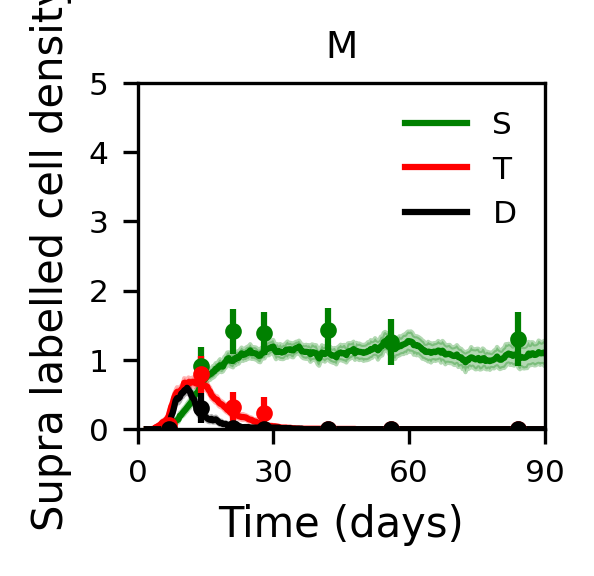

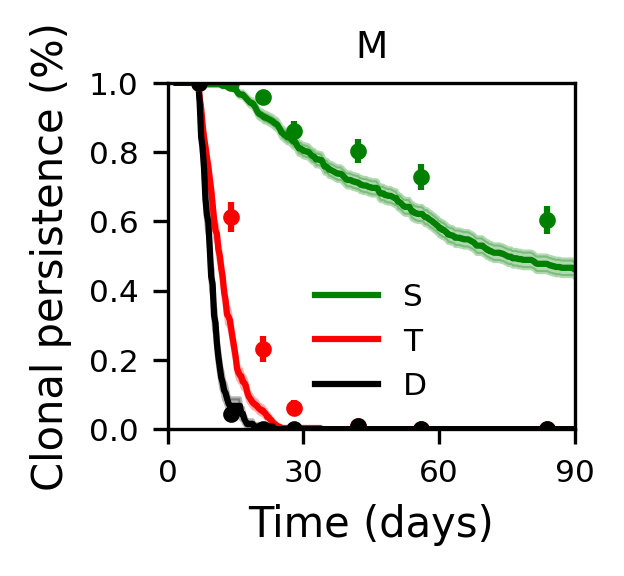

Already cropped


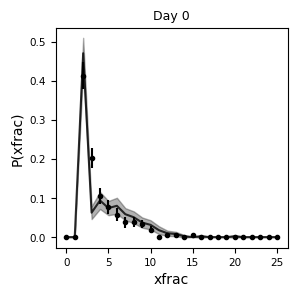








rsync -auv math:/store/BIOPHYS/jth42/glassy-tissue-turnover/S-T-D-model/ForPaper//modelling/SPD_0D_finale//hrun_SPD_0D_t_-30_n_1500_CVd_D_0.95_CVd_P_-1.0_CVd_S_0.5_corrDD_0.7_corrPD_0.0_corrPP_-1.0_corrSP_-1.0_corrSS_0.8_mu_50.0_q_0.875_r_0.15_refractP_-1.0_tau_100.0_seed_0.pkl ./modelling/SPD_0D_finale/ &
rsync -auv math:/store/BIOPHYS/jth42/glassy-tissue-turnover/S-T-D-model/ForPaper//modelling/SPD_0D_finale//hrun_SPD_0D_t_-30_n_1500_CVd_D_0.95_CVd_P_-1.0_CVd_S_0.5_corrDD_0.3_corrPD_1.0_corrPP_-1.0_corrSP_1.0_corrSS_0.0_mu_50.0_q_0.975_r_0.175_refractP_-1.0_tau_100.0_seed_0.pkl ./modelling/SPD_0D_finale/ &


In [ ]:
'''  
    Simulated annealing
'''

ncells = 1500
tau = 100.0
cST = 1.0
cTD = 0.0
cvS = 1.0
L = 20
hilln = 0.0
ncores = 1
i = -1



cols = {'M': 'r', 'F': 'b', 'castre': 'purple'}
sexname = {'M': 'M', 'F': 'F', 'castre': 'cM'}

sim_datasets = {}
exp_datasets = {}
best_fits = {}

freeParams = { 'r': [0.05,0.35], 
            'corrSS': [0.0,1.0], 
            'corrDD': [0.0,1.0],  
            'q': [0.1,0.5,1.0], #'rhoS': [rhoS],
            'mu': [25,100,200]}
extra_params = {}
extra_params['CVd_S'] = 0.5
extra_params['CVd_D'] = 1.0

cPD = 0.0
cSP = 1.0

for sex in ['M', 'F']:
    if sex == 'M':
        exp_file = '../../experiment/homeo/data_ctr_M.pkl'
        rhoS = 0.3
        cv_sb = 1.0
        q = 1.0
        r = 0.2
    elif sex == 'F':
        exp_file = '../../experiment/homeo/data_ctr_F.pkl'
        rhoS = 0.275
        cv_sb = 0.1   
        q = 1.0
        r = 0.2
    else:
        exp_file = '../../experiment/homeo/data_castre.pkl'
        rhoS = 0.275
        cv_sb = 1.0    
        q = 1.0
        r = 0.2


    for mode in [0]:
        print(ncores, mode, sex)

        if mode == 0:
            savefolder = 'modelling/SPD_0D_finale/'
            nseeds = 1
            
            params = {'tau': tau, 'refractP': -1, 'corrPP': -1.0,
                        'CVd_P': -1.0, 'corrPD': cPD,
                        'corrSP':  cSP}
            s0 = topt.sim_anneal(sim_model.SPD_0D, freeParams,
                                params = {**params, **extra_params}, simtype = 'h',
                            exp_file = exp_file,  exp_prefix = 'ctr', tshift = 2.0, metrics = mets,
                            compute_kwargs = compute_kwargs, toCalculate = toCalculate,
                        move_seed = np.abs(i),  use_linear = ['r', 'rhoS', 'q', 'CVd_S', 'CVd_D', 'corrSP', 'corrDD', 'corrSS', 'mu'],
                        move_sizes =     {'r': 0.025, 'rhoS':  0.025, 'q': 0.025, 'CVd_S':  0.05, 'CVd_D':  0.05, 'corrSP':  0.1, 'corrDD':  0.1, 'corrSS':  0.1, 'mu': 25},
                        free_param_min = {'r': 0.00, 'rhoS':   0.1, 'q':  0.0, 'CVd_S':  0.0, 'CVd_D':  0.0, 'corrSP':  0.0, 'corrDD':  0.0, 'corrSS':  0.0, 'mu': 25},
                        free_param_max = {'r': 1.00, 'rhoS':   1.0, 'q':  1.01, 'CVd_S': 1.04, 'CVd_D': 1.04, 'corrSP': 1.04, 'corrDD': 1.04, 'corrSS': 1.04, 'mu': 500},
                        use_momentum = False)

        elif mode == 1:
            savefolder = 'modelling/SPD_2D_finale/'
            nseeds = ncores
            params = {'tau': tau, 'refractP': -1, 'corrPP': -1.0,
                            'CVd_P': -1.0, 'corrPD': cPD, 'rhoS': rhoS,
                            'corrSP':  cSP, 
                            'L': L, 'hilln': hilln}
            s0 = topt.sim_anneal(sim_model.SPD_size, freeParams,
                                params = {**params, **extra_params}, simtype = 'h',
                            exp_file = exp_file,  exp_prefix = 'ctr', tshift = 2.0, metrics = mets,
                            compute_kwargs = compute_kwargs, toCalculate = toCalculate,
                        move_seed = np.abs(i),  use_linear = ['r', 'rhoS', 'q', 'CVd_S', 'CVd_D', 'corrSP', 'corrDD', 'corrSS'],
                        move_sizes =     {'r': 0.025, 'rhoS':  0.025, 'q': 0.025, 'CVd_S':  0.05, 'CVd_D':  0.05, 'corrSP':  0.1, 'corrDD':  0.1, 'corrSS':  0.1},
                        free_param_min = {'r': 0.00, 'rhoS':   0.1, 'q':  0.0, 'CVd_S':  0.0, 'CVd_D':  0.0, 'corrSP':  0.0, 'corrDD':  0.0, 'corrSS':  0.0},
                        free_param_max = {'r': 1.00, 'rhoS':   1.0, 'q':  1.01, 'CVd_S': 1.04, 'CVd_D': 1.04, 'corrSP': 1.04, 'corrDD': 1.04, 'corrSS': 1.04},
                        use_momentum = False)    
            
        s0.load_existing(tsteps = -30, ncells = ncells, savefolder = savefolder, 
                        tscalevals = -np.arange(2,14,0.05), 
                        shedvals = -np.arange(0.2, 2.0, 0.1), 
                        postopt_params = {'sbas_cv': np.arange(0.1, 1.01, 0.1)})
        
        for met in ['ll_SPD', 'full']: #'ll_STD', 
            print(sex, s0.searchspace[met].min(), met)
            best_fits[(savefolder, sex, met)] = s0.best_fit(met)
            print(s0.sim_save_name(-30, ncells, int(best_fits[(savefolder, sex, met)].name), 0))
            
            if s0.searchspace[met].min() >= 1e10:
                print('Missing fit')
                continue
            
            #continue
            sim_data = s0.get_best_fit(met, -30, ncells, savefolder = savefolder, nseeds = 1, 
                                       save_results = True, skip = 5, print_fit = False,
                                        norun = True)
            exp_data = s0.exp_data



            sdt = sim_data.data_time_crop()
            sim_datasets[sex] = sdt
            exp_datasets[sex] = exp_data
            #assert(0)

            if sex in ['M', 'F']:
                figfolder = 'Fig3_two_progenitor/F3_'
                axs = ds.plot_dist('S2like.supraCS', sdt, exp_data, subtimes= None, maxbin = 25, cdf = False, 
                            xlabel= 'Supra clone size', prelabel= f'{sexname[sex]} sup', bootSEs=True, color = f'{cols[sex]}', 
                                ncols=8, im_width = 1.0, ymax = 1.0, xmax = [10, 10, 10, 10,10,10,10,10],
                                ylabel = 'Frequency', nolegend = False, yscale = 1.5, num_xticks = 3, nogaps = True, 
                                yticks = [0,0.5,1.0])
                plt.savefig(f'Figures/{figfolder}{sexname[sex]}_supra_pdf.pdf', dpi = 300)

                axs = ds.plot_dist('S2like.basalCS', sdt, exp_data, subtimes= None, maxbin = 25, cdf = False, xlabel= 'Basal clone size', prelabel= f'{sexname[sex]} bas', bootSEs=True, color = f'{cols[sex]}',
                                ncols=8, im_width = 1.0, ymax = 0.6, xmax = [10, 10, 20, 20,20,20,20,20],
                                ylabel = 'Frequency', nolegend = False, yscale = 1.4, num_xticks = 3, nogaps = True,
                                yticks = [0, 0.3, 0.6])
                plt.savefig(f'Figures/{figfolder}{sexname[sex]}_basal_pdf.pdf', dpi = 300)

                axs = ds.plot_dist('S2like.supraCS', sdt, exp_data, subtimes = np.array([1,3,4,6]), maxbin = 25, cdf = False, 
                            xlabel= 'Supra clone size', prelabel= f'{sexname[sex]} sup', bootSEs=True, color = f'{cols[sex]}', 
                                ncols=4, im_width = 1.0, ymax = 1.0, xmax = [10,10,10,10],
                                ylabel = 'Frequency', nolegend = False, yscale = 1.4, num_xticks = 3, nogaps = True, 
                                yticks = [0,0.5,1.0])
                #plt.tight_layout()
                plt.savefig(f'Figures/{figfolder}{sexname[sex]}_supra_pdf_short.pdf', dpi = 300)

                axs = ds.plot_dist('S2like.basalCS', sdt, exp_data, subtimes = np.array([1,3,4,6]), maxbin = 25, cdf = False, 
                                   xlabel= 'Basal clone size', prelabel= f'{sexname[sex]} bas', bootSEs=True, color = f'{cols[sex]}',
                                ncols=4, im_width = 1.0, ymax = 0.8, xmax = [10,10,10,10],
                                ylabel = 'Frequency', nolegend = False, yscale = 1.4, num_xticks = 3, nogaps = True,
                                yticks = [0, 0.4, 0.8])
                #plt.tight_layout()                
                plt.savefig(f'Figures/{figfolder}{sexname[sex]}_basal_pdf_short.pdf', dpi = 300)                
                
            else:
                figfolder = 'Fig4_castrated/F4_'

                axs = ds.plot_dist('S2like.supraCS', sdt, exp_data, subtimes= None, maxbin = 25, cdf = False, 
                            xlabel= 'Supra clone size', prelabel= f'{sexname[sex]} sup', bootSEs=True, color = f'{cols[sex]}', 
                                ncols=6, im_width = 1.0, ymax = 1.0, xmax = [10, 10, 10, 10,10,10,10,10],
                                ylabel = 'Frequency', nolegend = True, yscale = 1.5, num_xticks = 3, nogaps = True, 
                                yticks = [0,0.5,1.0])
                plt.savefig(f'Figures/{figfolder}{sexname[sex]}_supra_pdf.pdf', dpi = 300)


                axs = ds.plot_dist('S2like.basalCS', sdt, exp_data, subtimes= None, maxbin = 25, cdf = False, xlabel= 'Basal clone size', prelabel= f'{sexname[sex]} bas', bootSEs=True, color = f'{cols[sex]}',
                                ncols=6, im_width = 1.0, ymax = 0.8, xmax = [10, 10, 20, 20,20,20,20,20],
                                ylabel = 'Frequency', nolegend = True, yscale = 1.5, num_xticks = 3, nogaps = True,
                                yticks = [0, 0.4, 0.8])
                plt.savefig(f'Figures/{figfolder}{sexname[sex]}_basal_pdf.pdf', dpi = 300)



            plt.figure(figsize = (1.75,1.5), dpi = 300)  
            ds.plot_quantity('S4like.basalCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Avg. sur clone size', plot_seeded = False, bootSEs = True, prelabel = 'basal', color = cols[sex], xfmt = 'o', sfmt = '-')
            ds.plot_quantity('S4like.supraCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Average clone size (cells)', plot_seeded = False, bootSEs = True, prelabel = 'supra', color = 'k', xfmt = '^', sfmt = '-')
            plt.xlim([0,90])
            plt.ylim([0,8])
            plt.xticks(np.arange(0, 91, 30))
            plt.legend(frameon = False)
            plt.title(sex + ': S-like')
            plt.savefig(f'Figures/{figfolder}{sexname[sex]}_av_size_S4.pdf', dpi = 300)
            plt.show() 


            plt.figure(figsize = (1.75,1.5), dpi = 300)
            ds.plot_quantity('T3like.basalCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Avg. sur clone size', plot_seeded = False, bootSEs = True, prelabel = 'basal', color = cols[sex], xfmt = 'o', sfmt = '-')
            ds.plot_quantity('T3like.supraCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Average clone size (cells)', plot_seeded = False, bootSEs = True, prelabel = 'supra', color = 'k', xfmt = '^', sfmt = '-')
            plt.xlim([0,30])
            plt.ylim([0,3])
            plt.xticks(np.arange(0, 31, 10))
            plt.legend(frameon = False)
            plt.title(sex + ': P3-like')
            plt.savefig(f'Figures/{figfolder}{sexname[sex]}_av_size_P3.pdf', dpi = 300)
            plt.show() 


            plt.figure(figsize = (1.75,1.5), dpi = 300)  
            ds.plot_quantity('Tlike.basalCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Avg. sur clone size', plot_seeded = False, bootSEs = True, prelabel = 'basal', color = cols[sex], xfmt = 'o', sfmt = '-')
            ds.plot_quantity('Tlike.supraCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Average clone size (cells)', plot_seeded = False, bootSEs = True, prelabel = 'supra', color = 'k', xfmt = '^', sfmt = '-')
            plt.xlim([0,30])
            plt.ylim([0,3])
            plt.xticks(np.arange(0, 31, 10))
            plt.legend(frameon = False)
            plt.title(sex + ': P-like')
            plt.savefig(f'Figures/{figfolder}{sexname[sex]}_av_size_P2.pdf', dpi = 300)
            plt.show() 


            plt.figure(figsize = (1.75,1.5), dpi = 300)  
            ds.plot_quantity('Dlike.basalCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Avg. sur clone size', plot_seeded = False, bootSEs = True, prelabel = 'basal', color = cols[sex], xfmt = 'o', sfmt = '-')
            ds.plot_quantity('Dlike.supraCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Avg. sur clone size', plot_seeded = False, bootSEs = True, prelabel = 'supra', color = 'k', xfmt = '^', sfmt = '-')
            plt.xlim([0,30])
            plt.ylim([0,1])
            plt.xticks(np.arange(0, 31, 10))
            plt.legend(frameon = False)
            plt.title(sex)
            plt.savefig(f'Figures/{figfolder}{sexname[sex]}_av_size_D.pdf', dpi = 300)
            plt.show()             



            plt.figure(figsize = (1.75,1.5), dpi = 300)
            ds.plot_quantity('S4like.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'SC', color = 'g')
            #ds.plot_quantity('T3like.lcd', sim_data, exp_data, sim_data.tscalevals[0],
            #                ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'T3', color = 'tab:orange')
            ds.plot_quantity('CPlike.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'TA', color = 'r')           
            ds.plot_quantity('Dlike.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Basal labelled cell density', plot_seeded = False, bootSEs = True, prelabel = 'D', color = 'k')    
            #plt.title(sex)
            plt.xlim([0,30])
            plt.ylim([0,5])
            plt.xticks(np.arange(0, 91, 30))
            plt.legend(frameon = False)
            plt.title(sex)
            plt.savefig(f'Figures/{figfolder}{sexname[sex]}_basal_lcd.pdf', dpi = 300)
            plt.show() 

            plt.figure(figsize = (1.75,1.5), dpi = 300)
            ds.plot_quantity('S4like.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'S', color = 'g')
            ds.plot_quantity('T3like.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'T3', color = 'tab:orange')
            ds.plot_quantity('Tlike.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'T', color = 'r')           
            ds.plot_quantity('Dlike.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Basal labelled cell density', plot_seeded = False, bootSEs = True, prelabel = 'D', color = 'k')    
            #plt.title(sex)
            plt.xlim([0,30])
            plt.ylim([0,5])
            plt.xticks(np.arange(0, 91, 30))
            plt.legend(frameon = False)
            plt.title(sex)
            plt.savefig(f'Figures/{figfolder}{sexname[sex]}_basal_lcd.pdf', dpi = 300)
            plt.show() 

            plt.figure(figsize = (1.75,1.5), dpi = 300)
            ds.plot_quantity('S4like.fullsupraCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'S', color = 'g')
            #ds.plot_quantity('T3like.lcd', sim_data, exp_data, sim_data.tscalevals[0],
            #                ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'T3', color = 'tab:orange')
            ds.plot_quantity('CPlike.fullsupraCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'T', color = 'r')           
            ds.plot_quantity('Dlike.fullsupraCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Supra labelled cell density', plot_seeded = False, bootSEs = True, prelabel = 'D', color = 'k')    
            #plt.title(sex)
            plt.xlim([0,30])
            plt.ylim([0,5])
            plt.xticks(np.arange(0, 91, 30))
            plt.legend(frameon = False)
            plt.title(sex)
            plt.savefig(f'Figures/{figfolder}{sexname[sex]}_supra_lcd.pdf', dpi = 300)
            plt.show()             

            plt.figure(figsize = (1.75,1.5), dpi = 300)
            ds.plot_quantity('S4like.pers', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Persistence', plot_seeded = False, bootSEs = True, prelabel = 'S', color = 'g')
            #ds.plot_quantity('T3like.pers', sim_data, exp_data, sim_data.tscalevals[0],
            #                ylabel = 'Persistence', plot_seeded = False, bootSEs = True, prelabel = 'T3', color = 'tab:orange')
            ds.plot_quantity('CPlike.pers', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Persistence', plot_seeded = False, bootSEs = True, prelabel = 'T', color = 'r')
            ds.plot_quantity('Dlike.pers', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Clonal persistence (%)', plot_seeded = False, bootSEs = True, prelabel = 'D', color = 'k')    
            #plt.title(sex)
            plt.xlim([0,90])
            plt.ylim([0,1])
            plt.xticks(np.arange(0, 91, 30))
            plt.legend(frameon = False)
            plt.title(sex)
            plt.savefig(f'Figures/{figfolder}{sexname[sex]}_persistence.pdf', dpi = 300)
            plt.show() 



            plt.figure(figsize=(3,3))
            axs = ds.plot_dist('S2like.xfrac', sdt, exp_data, subtimes= np.arange(1), 
                            maxbin = 25, cdf = False, xlabel= 'xfrac', bootSEs=True, 
                            ncols = 1, im_width = 3, subplot_axs = plt.gca())
            plt.show()             

            print('\n\n')
            
            continue
        
    
print('\n\n\n')



In [ ]:
params = pd.DataFrame(best_fits).T[['r', 'rhoS', 'q', 'CVd_S', 'CVd_D', 'corrSP', 'corrPD', 'corrDD', 'corrSS', 'delta', 'tscale', 'tau', 'shed']]
params['tauP' ] = params['tau']
params['mu'] = (params['q']*(1 - params['rhoS'])*(-1 + 2*params['delta'])*params['tau'] + params['rhoS']*params['tauP'])/(params['rhoS']*(-1 + params['q']*(-1 + 2*params['delta'])))
params['rhoS'] = (params['q']*(1 - 2*params['delta'])*params['tau'])/(params['q']*(1 - 2*params['delta'])*params['tau'] + (1 + params['q']*(1 - 2*params['delta']))*params['mu'] + params['tauP'])
params['rhoP'] = params['tauP']/(params['q']*(1 - 2*params['delta'])*params['tau'] + (1 + params['q']*(1 - 2*params['delta']))*params['mu'] + params['tauP'])
params['rhoD'] = ((1 + params['q']*(1 - 2*params['delta']))*params['mu'])/(params['q']*(1 - 2*params['delta'])*params['tau'] + (1 + params['q']*(1 - 2*params['delta']))*params['mu'] + params['tauP'])
params['mu'] /= params['tau']/params['tscale']

params